# Lab 2. Image filters on GPU (CUDA) and overhead analysis
- Filters: Gaussian blur, Sobel edge detection, median filter (noise reduction).
- For each filter: read PNG → pixel array → copy to GPU → CUDA kernel → copy back → save PNG.
- The same filter on the CPU; compare times and measure the GPU overhead (memory allocation, copies).
- Image sizes: 512×512, 1920×1080, 3840×2160 (4K). Grayscale images, global memory only.
- GPU: Tesla T4 (Colab). Run cells from top to bottom.

Student: Ye Naung, group 25225

### GPU check
- Shows the GPU model (Tesla T4).

In [1]:
!nvidia-smi

Thu Oct 22 09:45:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   60C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Image library (stb)
- `stb_image.h` reads PNG/JPG, `stb_image_write.h` writes PNG. Each is one header file, no installation needed.

In [2]:
!wget -q https://raw.githubusercontent.com/nothings/stb/master/stb_image.h
!wget -q https://raw.githubusercontent.com/nothings/stb/master/stb_image_write.h
!ls -l stb_image*.h

-rw-r--r-- 1 root root 283010 Oct 22 09:45 stb_image.h
-rw-r--r-- 1 root root  71221 Oct 22 09:45 stb_image_write.h


### Test image
- Download the test image (coffee cup, from the scikit-image library) as `input.png`.
- To use your own photo instead, upload it as `input.png` and skip the `wget` line.

In [3]:
!wget -q -O input.png https://raw.githubusercontent.com/scikit-image/scikit-image/v0.24.0/skimage/data/coffee.png
!ls -l input.png

-rw-r--r-- 1 root root 466706 Oct 22 09:45 input.png


### Images of 3 sizes
- The image is converted to grayscale and resized to 3 sizes: `img_512.png`, `img_1080.png`, `img_4k.png`.
- For the median filter, noisy copies are made (`noisy_*.png`): 3% of pixels become black or white (salt-and-pepper noise).

In [4]:
import numpy as np
from PIL import Image

base = Image.open("input.png").convert("L")   # grayscale
print("Original size:", base.size)

sizes = {"512": (512, 512), "1080": (1920, 1080), "4k": (3840, 2160)}
rng = np.random.default_rng(0)
for name, (w, h) in sizes.items():
    im = base.resize((w, h))
    im.save(f"img_{name}.png")
    a = np.array(im)
    m = rng.random(a.shape)
    a[m < 0.015] = 0       # black points
    a[m > 0.985] = 255     # white points
    Image.fromarray(a).save(f"noisy_{name}.png")
    print(f"img_{name}.png  noisy_{name}.png  {w}x{h}")

Original size: (600, 400)
img_512.png  noisy_512.png  512x512
img_1080.png  noisy_1080.png  1920x1080
img_4k.png  noisy_4k.png  3840x2160


### Part 1. Libraries
- `%%writefile` creates `lab2.cu`, next cells add code with `%%writefile -a`.
- chrono – CPU timer; stb – reading and writing PNG files.

In [5]:
%%writefile lab2.cu
// =====================================================================
// Laboratory Assignment 2
// Image filters on GPU (CUDA) vs CPU: blur, Sobel, median
// =====================================================================

// ===== Part 1. Libraries =====
#include <cstdio>
#include <cstdlib>
#include <cmath>
#include <chrono>
#include <cuda_runtime.h>

#define STB_IMAGE_IMPLEMENTATION
#include "stb_image.h"
#define STB_IMAGE_WRITE_IMPLEMENTATION
#include "stb_image_write.h"

Writing lab2.cu


### Part 2. CHECK macro and constants
- CHECK stops the program if a CUDA function returns an error.
- Block size 16×16 = 256 threads (2D block). The kernel is repeated 10 times to average its time; the CPU filter 3 times.

In [6]:
%%writefile -a lab2.cu

// ===== Part 2. CHECK macro and constants =====
#define CHECK(call)                                                   \
    do {                                                              \
        cudaError_t e = (call);                                       \
        if (e != cudaSuccess) {                                       \
            fprintf(stderr, "CUDA error: %s (%s:%d)\n",               \
                    cudaGetErrorString(e), __FILE__, __LINE__);       \
            exit(1);                                                  \
        }                                                             \
    } while (0)

constexpr int BLOCK       = 16;   // block 16 x 16 threads
constexpr int REPEATS     = 10;   // kernel repeats for time averaging
constexpr int CPU_REPEATS = 3;    // CPU repeats for time averaging

constexpr int F_BLUR   = 0;
constexpr int F_SOBEL  = 1;
constexpr int F_MEDIAN = 2;
const char* NAMES[] = {"Gaussian blur", "Sobel", "Median"};
const char* FILES[] = {"blur", "sobel", "median"};

double ms_since(std::chrono::high_resolution_clock::time_point t0) {
    auto t1 = std::chrono::high_resolution_clock::now();
    return std::chrono::duration<double, std::milli>(t1 - t0).count();
}

Appending to lab2.cu


### Part 3. Filters for one pixel (common for CPU and GPU)
- `__host__ __device__` – the same function can run on the CPU and on the GPU, so both versions use an identical algorithm.
- `get_px` – reads a pixel with **clamping**: coordinates outside the image are moved to the nearest edge (border / halo problem).
- **Gaussian blur** – 3×3 window, weights 1-2-1 / 2-4-2 / 1-2-1, sum divided by 16.
- **Sobel** – horizontal (Gx) and vertical (Gy) gradients, result = √(Gx² + Gy²), limited to 255.
- **Median** – 9 values of the 3×3 window are sorted, the middle one is taken (removes black/white noise points).

In [7]:
%%writefile -a lab2.cu

// ===== Part 3. Filters for one pixel (CPU and GPU) =====
__host__ __device__ int clampi(int v, int lo, int hi) {
    return v < lo ? lo : (v > hi ? hi : v);
}

// pixel (x, y) with clamping at the image border
__host__ __device__ int get_px(const unsigned char* img, int w, int h, int x, int y) {
    x = clampi(x, 0, w - 1);
    y = clampi(y, 0, h - 1);
    return img[y * w + x];
}

__host__ __device__ unsigned char blur_px(const unsigned char* img, int w, int h, int x, int y) {
    const int k[3][3] = {{1, 2, 1}, {2, 4, 2}, {1, 2, 1}};
    int sum = 0;
    for (int dy = -1; dy <= 1; ++dy)
        for (int dx = -1; dx <= 1; ++dx)
            sum += k[dy + 1][dx + 1] * get_px(img, w, h, x + dx, y + dy);
    return (unsigned char)(sum / 16);
}

__host__ __device__ unsigned char sobel_px(const unsigned char* img, int w, int h, int x, int y) {
    const int kx[3][3] = {{-1, 0, 1}, {-2, 0, 2}, {-1, 0, 1}};
    const int ky[3][3] = {{-1, -2, -1}, {0, 0, 0}, {1, 2, 1}};
    int gx = 0, gy = 0;
    for (int dy = -1; dy <= 1; ++dy)
        for (int dx = -1; dx <= 1; ++dx) {
            int p = get_px(img, w, h, x + dx, y + dy);
            gx += kx[dy + 1][dx + 1] * p;
            gy += ky[dy + 1][dx + 1] * p;
        }
    float m = sqrtf((float)(gx * gx + gy * gy));
    if (m > 255.0f) m = 255.0f;
    return (unsigned char)m;
}

__host__ __device__ unsigned char median_px(const unsigned char* img, int w, int h, int x, int y) {
    int v[9];
    int n = 0;
    for (int dy = -1; dy <= 1; ++dy)
        for (int dx = -1; dx <= 1; ++dx)
            v[n++] = get_px(img, w, h, x + dx, y + dy);
    // insertion sort of 9 values
    for (int i = 1; i < 9; ++i) {
        int t = v[i], j = i - 1;
        while (j >= 0 && v[j] > t) { v[j + 1] = v[j]; --j; }
        v[j + 1] = t;
    }
    return (unsigned char)v[4];
}

__host__ __device__ unsigned char apply_filter(int f, const unsigned char* img, int w, int h, int x, int y) {
    if (f == F_BLUR)  return blur_px(img, w, h, x, y);
    if (f == F_SOBEL) return sobel_px(img, w, h, x, y);
    return median_px(img, w, h, x, y);
}

Appending to lab2.cu


### Part 4. CPU version and GPU kernel
- **CPU:** two loops over all pixels (rows y, columns x).
- **GPU:** 2D grid of 2D blocks, one thread = one pixel. `x = blockIdx.x * blockDim.x + threadIdx.x`, `y = blockIdx.y * blockDim.y + threadIdx.y`.
- The image is stored row by row in a 1D array: `index = y * width + x`.
- `if (x < w && y < h)` – the grid is a bit larger than the image, extra threads do nothing.

In [8]:
%%writefile -a lab2.cu

// ===== Part 4. CPU version and GPU kernel =====
void filter_cpu(const unsigned char* in, unsigned char* out, int w, int h, int f) {
    for (int y = 0; y < h; ++y)
        for (int x = 0; x < w; ++x)
            out[y * w + x] = apply_filter(f, in, w, h, x, y);
}

__global__ void filter_kernel(const unsigned char* in, unsigned char* out, int w, int h, int f) {
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;
    if (x < w && y < h)
        out[y * w + x] = apply_filter(f, in, w, h, x, y);
}

Appending to lab2.cu


### Part 5. GPU pipeline with time measurement
- **alloc** – `cudaMalloc` for input and output (CPU timer).
- **H2D** – copy CPU → GPU, **kernel** – average of 10 launches, **D2H** – copy GPU → CPU (CUDA Events).
- **total** = alloc + H2D + kernel + D2H – the full GPU time for one image, comparable with the CPU time.

In [9]:
%%writefile -a lab2.cu

// ===== Part 5. GPU pipeline with time measurement =====
struct GpuTime { double alloc, h2d, kernel, d2h, total; };

GpuTime filter_gpu(const unsigned char* h_in, unsigned char* h_out, int w, int h, int f) {
    GpuTime t;
    size_t bytes = (size_t)w * h;
    cudaEvent_t start, stop;
    CHECK(cudaEventCreate(&start));
    CHECK(cudaEventCreate(&stop));
    float ms = 0.0f;

    // 1. Memory allocation on the GPU
    auto t0 = std::chrono::high_resolution_clock::now();
    unsigned char *d_in = nullptr, *d_out = nullptr;
    CHECK(cudaMalloc(&d_in, bytes));
    CHECK(cudaMalloc(&d_out, bytes));
    t.alloc = ms_since(t0);

    // 2. Copy CPU -> GPU
    CHECK(cudaEventRecord(start));
    CHECK(cudaMemcpy(d_in, h_in, bytes, cudaMemcpyHostToDevice));
    CHECK(cudaEventRecord(stop));
    CHECK(cudaEventSynchronize(stop));
    CHECK(cudaEventElapsedTime(&ms, start, stop));
    t.h2d = ms;

    // 3. Kernel: 2D grid of 2D blocks
    dim3 block(BLOCK, BLOCK);
    dim3 grid((w + BLOCK - 1) / BLOCK, (h + BLOCK - 1) / BLOCK);
    CHECK(cudaEventRecord(start));
    for (int r = 0; r < REPEATS; ++r)
        filter_kernel<<<grid, block>>>(d_in, d_out, w, h, f);
    CHECK(cudaEventRecord(stop));
    CHECK(cudaEventSynchronize(stop));
    CHECK(cudaGetLastError());
    CHECK(cudaEventElapsedTime(&ms, start, stop));
    t.kernel = ms / REPEATS;

    // 4. Copy GPU -> CPU
    CHECK(cudaEventRecord(start));
    CHECK(cudaMemcpy(h_out, d_out, bytes, cudaMemcpyDeviceToHost));
    CHECK(cudaEventRecord(stop));
    CHECK(cudaEventSynchronize(stop));
    CHECK(cudaEventElapsedTime(&ms, start, stop));
    t.d2h = ms;

    CHECK(cudaFree(d_in));
    CHECK(cudaFree(d_out));
    CHECK(cudaEventDestroy(start));
    CHECK(cudaEventDestroy(stop));

    t.total = t.alloc + t.h2d + t.kernel + t.d2h;
    return t;
}

Appending to lab2.cu


### Part 6. main
- Arguments: input image, noisy image (for the median filter), prefix for output files.
- `cudaFree(0)` creates the CUDA context – its time is printed separately (**CUDA init**, a one-time overhead).
- `stbi_load(..., 1)` reads the PNG as grayscale (1 byte per pixel).
- Warm-up: one GPU run without measuring.
- For each filter: CPU time, GPU times, check that CPU and GPU images are identical, save the GPU result as PNG.

In [10]:
%%writefile -a lab2.cu

// ===== Part 6. main =====
int main(int argc, char** argv) {
    if (argc < 4) {
        printf("usage: ./lab2 image.png noisy.png out_prefix\n");
        return 1;
    }

    // CUDA initialization (one-time overhead)
    auto t0 = std::chrono::high_resolution_clock::now();
    CHECK(cudaFree(0));
    double init_ms = ms_since(t0);

    // Read images as grayscale
    int w, h, c, w2, h2;
    unsigned char* img   = stbi_load(argv[1], &w, &h, &c, 1);
    unsigned char* noisy = stbi_load(argv[2], &w2, &h2, &c, 1);
    if (!img || !noisy || w != w2 || h != h2) {
        printf("cannot read images\n");
        return 1;
    }
    size_t bytes = (size_t)w * h;
    unsigned char* out_cpu = (unsigned char*)malloc(bytes);
    unsigned char* out_gpu = (unsigned char*)malloc(bytes);

    printf("Image: %d x %d (%.1f MB), CUDA init: %.1f ms\n", w, h, bytes / 1e6, init_ms);

    filter_gpu(img, out_gpu, w, h, F_BLUR);   // warm-up

    printf("%-14s| CPU, ms  | alloc | H2D   | kernel | D2H   | GPU total | speedup kernel | speedup total | diff\n", "Filter");
    printf("--------------+----------+-------+-------+--------+-------+-----------+----------------+---------------+-----\n");

    for (int f = 0; f < 3; ++f) {
        const unsigned char* in = (f == F_MEDIAN) ? noisy : img;

        // CPU
        auto c0 = std::chrono::high_resolution_clock::now();
        for (int r = 0; r < CPU_REPEATS; ++r)
            filter_cpu(in, out_cpu, w, h, f);
        double cpu_ms = ms_since(c0) / CPU_REPEATS;

        // GPU
        GpuTime g = filter_gpu(in, out_gpu, w, h, f);

        // Check: number of different pixels between CPU and GPU results
        long long diff = 0;
        for (size_t i = 0; i < bytes; ++i)
            if (out_cpu[i] != out_gpu[i]) ++diff;

        // Save the GPU result
        char name[256];
        snprintf(name, sizeof(name), "%s_%s.png", argv[3], FILES[f]);
        stbi_write_png(name, w, h, 1, out_gpu, w);

        printf("%-14s| %8.2f | %5.2f | %5.2f | %6.3f | %5.2f | %9.2f | %14.1f | %13.2f | %lld\n",
               NAMES[f], cpu_ms, g.alloc, g.h2d, g.kernel, g.d2h, g.total,
               cpu_ms / g.kernel, cpu_ms / g.total, diff);
    }

    stbi_image_free(img);
    stbi_image_free(noisy);
    free(out_cpu);
    free(out_gpu);
    return 0;
}

Appending to lab2.cu


### Compile
- `-O2` – optimization (for both CPU and GPU code), `-arch=sm_75` – Tesla T4.
- Warnings from the stb library can be ignored.

In [11]:
!nvcc -O2 -arch=sm_75 lab2.cu -o lab2

stb_image.h(4276): warning #550-D: variable "old_limit" was set but never used
     unsigned int cur, limit, old_limit;
                              ^

Remark: The warnings can be suppressed with "-diag-suppress <warning-number>"

stb_image.h(5185): warning #550-D: variable "idata_limit_old" was set but never used
                 stbi__uint32 idata_limit_old = idata_limit;
                              ^

stb_image.h(6972): warning #550-D: variable "out_size" was set but never used
        int out_size = 0;
            ^

stb_image.h(6973): warning #550-D: variable "delays_size" was set but never used
        int delays_size = 0;
            ^



### Run for 3 image sizes
- Columns: CPU time, GPU parts (alloc, H2D, kernel, D2H), GPU total, speedup = CPU / GPU (kernel only and total), diff = number of different pixels (0 = CPU and GPU give the same image).

In [12]:
!./lab2 img_512.png  noisy_512.png  out_512
!./lab2 img_1080.png noisy_1080.png out_1080
!./lab2 img_4k.png   noisy_4k.png   out_4k

Image: 512 x 512 (0.3 MB), CUDA init: 307.2 ms
Filter        | CPU, ms  | alloc | H2D   | kernel | D2H   | GPU total | speedup kernel | speedup total | diff
--------------+----------+-------+-------+--------+-------+-----------+----------------+---------------+-----
Gaussian blur |     4.28 |  0.11 |  0.09 |  0.014 |  0.09 |      0.31 |          310.4 |         13.79 | 0
Sobel         |     6.72 |  0.18 |  0.10 |  0.014 |  0.09 |      0.37 |          490.1 |         17.93 | 0
Median        |    22.95 |  0.22 |  0.10 |  0.158 |  0.09 |      0.57 |          144.8 |         40.38 | 0
Image: 1920 x 1080 (2.1 MB), CUDA init: 219.2 ms
Filter        | CPU, ms  | alloc | H2D   | kernel | D2H   | GPU total | speedup kernel | speedup total | diff
--------------+----------+-------+-------+--------+-------+-----------+----------------+---------------+-----
Gaussian blur |    34.35 |  0.21 |  0.50 |  0.088 |  0.54 |      1.34 |          392.3 |         25.66 | 0
Sobel         |    52.58 |  0.30 |  

### Result images (1920×1080)

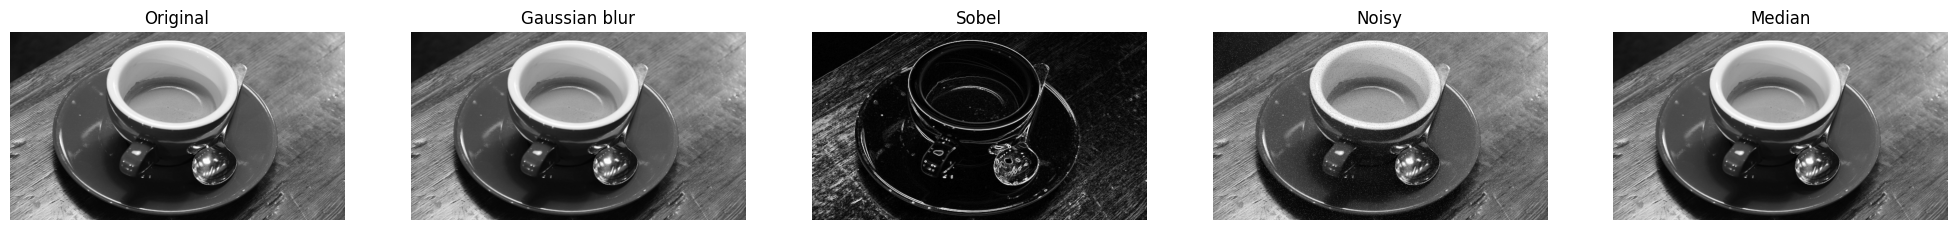

In [13]:
import matplotlib.pyplot as plt
from PIL import Image

files  = ["img_1080.png", "out_1080_blur.png", "out_1080_sobel.png", "noisy_1080.png", "out_1080_median.png"]
titles = ["Original", "Gaussian blur", "Sobel", "Noisy", "Median"]
fig, ax = plt.subplots(1, 5, figsize=(25, 4))
for a, f, t in zip(ax, files, titles):
    a.imshow(Image.open(f), cmap="gray", vmin=0, vmax=255)
    a.set_title(t)
    a.axis("off")
plt.show()

### Notes on results
- diff = 0: CPU and GPU produce the same image (same algorithm).
- The kernel is 75–650 times faster than the CPU – each pixel is computed by its own thread.
- With copies and allocation, the GPU is still faster for all sizes. Copies take most of the GPU time (e.g. ~84% for blur on 4K) – the program is data-transfer bound.
- CUDA initialization (~200–300 ms) is a one-time cost. If it is included, the CPU is faster for the small 512×512 image.
- Median has the smallest kernel speedup: sorting 9 values needs many comparisons and branches, which are slower on the GPU.